# Лабораторная работа № 1 — шаг 19

## Разведочный анализ стоимости авиабилетов

**Датасет:** [FlightPrices](https://www.kaggle.com/datasets/dilwong/flightprices), собранный из предложений Expedia. [Описание признаков автора](https://github.com/dilwong/FlightPrices/blob/master/README.md). На кластере уже доступен файл `/user/user0/datasets/itineraries_apr16_may17.csv` размером **4 782 917 140 байт (4,45 ГиБ)**. Файл используется только для чтения; копирование и изменение общего HDFS-каталога не выполняются. Анализ относится к имеющемуся в HDFS фрагменту исходного набора, поэтому его результаты не следует переносить на весь FlightPrices без оговорки.

Выполняются все требования шага 19: определение типов признаков, проверка и устранение пропусков, выявление и обработка выбросов, статистики с квартилями, распределения и корреляции. Для обработанных данных создаётся новая таблица в существующей базе `statskevich_database`; исходные таблицы остаются без изменений. Шаг 20 здесь не выполняется.


In [1]:
import os
import subprocess

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pyspark import SparkConf
from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F

assert os.getenv("USER") == "user0", "Ноутбук должен исполняться на удалённом узле от user0"
database_name = "statskevich_database"
source_path = "hdfs:///user/user0/datasets/itineraries_apr16_may17.csv"
source_size = int(subprocess.run(
    ["hdfs", "dfs", "-stat", "%b", source_path],
    text=True, capture_output=True, check=True,
).stdout.strip())
print(f"Объём исходного файла: {source_size:,} байт = {source_size / 1024**3:.2f} ГиБ")
assert source_size >= 3 * 1024**3, "Размер датасета не отвечает требованию нескольких гигабайт"


Объём исходного файла: 4,782,917,140 байт = 4.45 ГиБ


### 1. Spark и чтение исходного файла

Используется та же конфигурация YARN и Iceberg-каталога, что успешно работала в двух предыдущих ноутбуках. Сначала файл читается напрямую из HDFS, а после анализа очищенные данные записываются в новую таблицу Iceberg. Чтение CSV начинается без вывода типов, чтобы отдельно показать исходные строковые поля и обосновать преобразование.


In [2]:
conf = (SparkConf()
    .setAppName("lab1 step19 flight prices")
    .setMaster("yarn")
    .set("spark.submit.deployMode", "client")
    .set("spark.executor.memory", "12g")
    .set("spark.executor.cores", "8")
    .set("spark.executor.instances", "2")
    .set("spark.driver.memory", "4g")
    .set("spark.driver.cores", "2")
    .set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    .set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    .set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    .set("spark.sql.catalog.spark_catalog.type", "hadoop")
    .set("spark.sql.catalog.spark_catalog.warehouse", "hdfs:///user/user0/warehouse")
    .set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO"))
spark = SparkSession.builder.config(conf=conf).getOrCreate()
assert spark.sparkContext.master == "yarn", spark.sparkContext.master
print("Spark", spark.version, "; master", spark.sparkContext.master)
print("Существующие таблицы:", [t.name for t in spark.catalog.listTables(database_name)])
raw = spark.read.option("header", "true").option("mode", "PERMISSIVE").csv(source_path)
print("Исходная схема (все поля прочитаны как строки):")
raw.printSchema()
raw_n = raw.count()
print("Исходных строк:", raw_n)
assert raw_n > 0


:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-590bfbd9-fe17-4ca8-916e-eb5b5a4a6868;1.0
	confs: [default]


	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 636ms :: artifacts dl 23ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-590bfbd9-fe17-4ca8-916e-eb5b5a4a6868
	confs: [default]


	0 artifacts copied, 1 already retrieved (0kB/27ms)


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 22:46:19 WARN Client: Neither spark.yarn.jars nor spark.yarn.archive is set, falling back to uploading libraries under SPARK_HOME.


26/11/19 22:46:37 WARN Client: Same path resource file:///home/user0/.ivy2/jars/org.apache.iceberg_iceberg-spark-runtime-3.5_2.12-1.6.0.jar added multiple times to distributed cache.


Spark 3.5.2 ; master yarn


Существующие таблицы: ['sobd_lab1_table', 'sobd_lab1_processed_table']


Исходная схема (все поля прочитаны как строки):
root
 |-- legId: string (nullable = true)
 |-- searchDate: string (nullable = true)
 |-- flightDate: string (nullable = true)
 |-- startingAirport: string (nullable = true)
 |-- destinationAirport: string (nullable = true)
 |-- fareBasisCode: string (nullable = true)
 |-- travelDuration: string (nullable = true)
 |-- elapsedDays: string (nullable = true)
 |-- isBasicEconomy: string (nullable = true)
 |-- isRefundable: string (nullable = true)
 |-- isNonStop: string (nullable = true)
 |-- baseFare: string (nullable = true)
 |-- totalFare: string (nullable = true)
 |-- seatsRemaining: string (nullable = true)
 |-- totalTravelDistance: string (nullable = true)
 |-- segmentsDepartureTimeEpochSeconds: string (nullable = true)
 |-- segmentsDepartureTimeRaw: string (nullable = true)
 |-- segmentsArrivalTimeEpochSeconds: string (nullable = true)
 |-- segmentsArrivalTimeRaw: string (nullable = true)
 |-- segmentsArrivalAirportCode: string (nullabl

Исходных строк: 12857310


### 2. Типы признаков

`legId` — идентификатор; аэропорты, авиакомпания и признаки тарифа — категориальные; даты поиска и рейса — временные; цены, расстояние, число оставшихся мест и интервал между поиском и вылетом — количественные. Идентификатор `legId` не используется в расчёте средних и корреляций.


In [3]:
selected = raw.select(
    F.col("legId"),
    F.to_date("searchDate").alias("search_date"),
    F.to_date("flightDate").alias("flight_date"),
    F.col("startingAirport").alias("origin"),
    F.col("destinationAirport").alias("destination"),
    F.col("segmentsAirlineName").alias("airlines"),
    F.when(F.lower("isBasicEconomy") == "true", True).when(F.lower("isBasicEconomy") == "false", False).alias("basic_economy"),
    F.when(F.lower("isNonStop") == "true", True).when(F.lower("isNonStop") == "false", False).alias("nonstop"),
    F.col("baseFare").cast("double").alias("base_fare"),
    F.col("totalFare").cast("double").alias("total_fare"),
    F.col("totalTravelDistance").cast("double").alias("distance_miles"),
    F.col("seatsRemaining").cast("int").alias("seats_remaining"),
)
selected = selected.withColumn("days_to_departure", F.datediff("flight_date", "search_date"))
selected.printSchema()
display(pd.DataFrame([
    ("legId", "идентификатор"),
    ("search_date, flight_date", "временные"),
    ("origin, destination, airlines", "категориальные"),
    ("basic_economy, nonstop", "бинарные категориальные"),
    ("base_fare, total_fare, distance_miles, seats_remaining, days_to_departure", "количественные"),
], columns=["признаки", "вид"]))


root
 |-- legId: string (nullable = true)
 |-- search_date: date (nullable = true)
 |-- flight_date: date (nullable = true)
 |-- origin: string (nullable = true)
 |-- destination: string (nullable = true)
 |-- airlines: string (nullable = true)
 |-- basic_economy: boolean (nullable = true)
 |-- nonstop: boolean (nullable = true)
 |-- base_fare: double (nullable = true)
 |-- total_fare: double (nullable = true)
 |-- distance_miles: double (nullable = true)
 |-- seats_remaining: integer (nullable = true)
 |-- days_to_departure: integer (nullable = true)



,признаки,вид
0,legId,идентификатор
1,"search_date, flight_date",временные
2,"origin, destination, airlines",категориальные
3,"basic_economy, nonstop",бинарные категориальные
4,"base_fare, total_fare, distance_miles, seats_r...",количественные


### 3. Пропуски и ошибки преобразования типов

Для строк пропуском считается также пустое значение; для чисел — `NULL` или `NaN`. Пропуски считаются после преобразования типов, поэтому некорректные числовые строки тоже видны в отчёте. Даты и цены нужны для основного анализа: строки без них исключаются. Пропуски в расстоянии и числе мест заменяются медианами, а неизвестная авиакомпания обозначается `Unknown`.


In [4]:
fields = ["legId", "search_date", "flight_date", "origin", "destination", "airlines", "basic_economy", "nonstop", "base_fare", "total_fare", "distance_miles", "seats_remaining", "days_to_departure"]
numeric_fields = {"base_fare", "total_fare", "distance_miles", "seats_remaining", "days_to_departure"}
missing_expr = []
for name in fields:
    condition = F.col(name).isNull()
    if name in numeric_fields:
        condition = condition | F.isnan(F.col(name).cast("double"))
    elif name in {"legId", "origin", "destination", "airlines"}:
        condition = condition | (F.trim(F.col(name)) == "")
    missing_expr.append(F.sum(F.when(condition, 1).otherwise(0)).alias(name))
missing = selected.agg(*missing_expr).first().asDict()
display(pd.DataFrame([{"признак": name, "пропусков": missing[name], "доля, %": round(missing[name] / raw_n * 100, 3)} for name in fields]))


,признак,пропусков,"доля, %"
0,legId,0,0.000
1,search_date,0,0.000
2,flight_date,0,0.000
3,origin,0,0.000
4,destination,0,0.000
5,airlines,0,0.000
6,basic_economy,0,0.000
7,nonstop,0,0.000
8,base_fare,0,0.000
9,total_fare,0,0.000


In [5]:
valid = selected.filter(
    F.col("search_date").isNotNull()
    & F.col("flight_date").isNotNull()
    & F.col("origin").isNotNull() & (F.trim("origin") != "")
    & F.col("destination").isNotNull() & (F.trim("destination") != "")
    & F.col("base_fare").isNotNull() & ~F.isnan("base_fare")
    & F.col("total_fare").isNotNull() & ~F.isnan("total_fare")
    & (F.col("base_fare") >= 0) & (F.col("total_fare") > 0)
    & (F.col("base_fare") <= F.col("total_fare"))
    & F.col("days_to_departure").between(0, 365)
)
valid = valid.withColumn("airlines", F.when(F.col("airlines").isNull() | (F.trim("airlines") == ""), F.lit("Unknown")).otherwise(F.col("airlines")))
valid = valid.withColumn("distance_miles", F.when(F.col("distance_miles") < 0, F.lit(None)).otherwise(F.col("distance_miles")))
valid = valid.withColumn("seats_remaining", F.when(F.col("seats_remaining") < 0, F.lit(None)).otherwise(F.col("seats_remaining")))
distance_median = valid.filter(F.col("distance_miles").isNotNull() & ~F.isnan("distance_miles")).approxQuantile("distance_miles", [0.5], 0.001)[0]
seats_median = valid.filter(F.col("seats_remaining").isNotNull()).approxQuantile("seats_remaining", [0.5], 0.001)[0]
valid = valid.withColumn("distance_miles", F.when(F.col("distance_miles").isNull() | F.isnan("distance_miles"), F.lit(distance_median)).otherwise(F.col("distance_miles")))
valid = valid.withColumn("seats_remaining", F.when(F.col("seats_remaining").isNull(), F.lit(int(seats_median))).otherwise(F.col("seats_remaining")))
valid = valid.persist(StorageLevel.MEMORY_AND_DISK)
valid_n = valid.count()
print("После очистки пропусков и ошибок:", valid_n, "из", raw_n)
print("Удалено:", raw_n - valid_n)
print("Медиана расстояния:", distance_median, "; медиана мест:", seats_median)
print("Диапазон дат поиска и рейса:")
valid.agg(F.min("search_date"), F.max("search_date"), F.min("flight_date"), F.max("flight_date")).show()
assert valid_n > 0


После очистки пропусков и ошибок: 12857310 из 12857310
Удалено: 0
Медиана расстояния: 1392.0 ; медиана мест: 7.0
Диапазон дат поиска и рейса:


+----------------+----------------+----------------+----------------+
|min(search_date)|max(search_date)|min(flight_date)|max(flight_date)|
+----------------+----------------+----------------+----------------+
|      2022-04-16|      2022-05-17|      2022-04-17|      2022-07-12|
+----------------+----------------+----------------+----------------+



### 4. Статистики и выбросы

Расчёт включает количество, минимум, среднее, стандартное отклонение, три квартиля, 99,5-й процентиль и максимум. Слишком дорогие и слишком длинные маршруты выделяются по 99,5-му процентилю. Итоговый аналитический датафрейм исключает такие строки; исходный HDFS-файл сохраняется без изменений. Порог и число исключённых объектов показаны явно.


In [6]:
quantitative = ["base_fare", "total_fare", "distance_miles", "seats_remaining", "days_to_departure"]
stats = []
limits = {}
for name in quantitative:
    q25, q50, q75, q995 = valid.approxQuantile(name, [0.25, 0.5, 0.75, 0.995], 0.001)
    summary = valid.agg(F.count(name).alias("count"), F.min(name).alias("min"), F.mean(name).alias("mean"), F.stddev(name).alias("stddev"), F.max(name).alias("max")).first().asDict()
    stats.append({"признак": name, **summary, "Q1": q25, "медиана": q50, "Q3": q75, "P99.5": q995})
    limits[name] = q995
display(pd.DataFrame(stats))


,признак,count,min,mean,stddev,max,Q1,медиана,Q3,P99.5
0,base_fare,12857310,2.00,322.332260,193.793973,7662.33,180.47,295.81,430.7,1067.91
1,total_fare,12857310,23.97,372.466158,207.374951,8260.61,222.10,342.60,487.2,1180.49
2,distance_miles,12857310,97.00,1558.063030,812.979415,4430.00,903.00,1392.00,2308.0,3562.00
3,seats_remaining,12857310,0.00,5.651139,2.958016,10.00,3.00,7.00,8.0,10.00
4,days_to_departure,12857310,1.00,27.733532,17.302254,60.00,12.00,26.00,42.0,60.00


In [7]:
outlier_counts = valid.agg(*[
    F.sum(F.when(F.col(name) > limits[name], 1).otherwise(0)).alias(name)
    for name in ["total_fare", "distance_miles"]
]).first().asDict()
display(pd.DataFrame([{"признак": name, "порог P99.5": limits[name], "выбросов": outlier_counts[name]} for name in outlier_counts]))
clean = valid.filter((F.col("total_fare") <= limits["total_fare"]) & (F.col("distance_miles") <= limits["distance_miles"]))
clean = clean.persist(StorageLevel.MEMORY_AND_DISK)
clean_n = clean.count()
print("После обработки выбросов:", clean_n, "из", valid_n)
print("Удалено уникальных строк:", valid_n - clean_n)
assert 0 < clean_n <= valid_n


,признак,порог P99.5,выбросов
0,total_fare,1180.49,68032
1,distance_miles,3562.00,64187


После обработки выбросов: 12725169 из 12857310
Удалено уникальных строк: 132141


In [8]:
clean_stats = []
for name in quantitative:
    q25, q50, q75 = clean.approxQuantile(name, [0.25, 0.5, 0.75], 0.001)
    summary = clean.agg(F.min(name).alias("min"), F.mean(name).alias("mean"), F.stddev(name).alias("stddev"), F.max(name).alias("max")).first().asDict()
    clean_stats.append({"признак": name, **summary, "Q1": q25, "медиана": q50, "Q3": q75})
display(pd.DataFrame(clean_stats))


,признак,min,mean,stddev,max,Q1,медиана,Q3
0,base_fare,2.00,315.207789,170.164119,1113.00,179.54,293.02,426.05
1,total_fare,23.97,364.822617,181.909936,1180.49,219.60,341.58,481.60
2,distance_miles,97.00,1542.648415,799.205752,3562.00,895.00,1392.00,2282.00
3,seats_remaining,0.00,5.649517,2.963155,10.00,3.00,7.00,8.00
4,days_to_departure,1.00,27.730891,17.304746,60.00,12.00,26.00,42.00


### 5. Визуализация распределений

Количество записей по бинам и категориям подсчитывается на кластере; на драйвер передаются только десятки агрегированных значений.


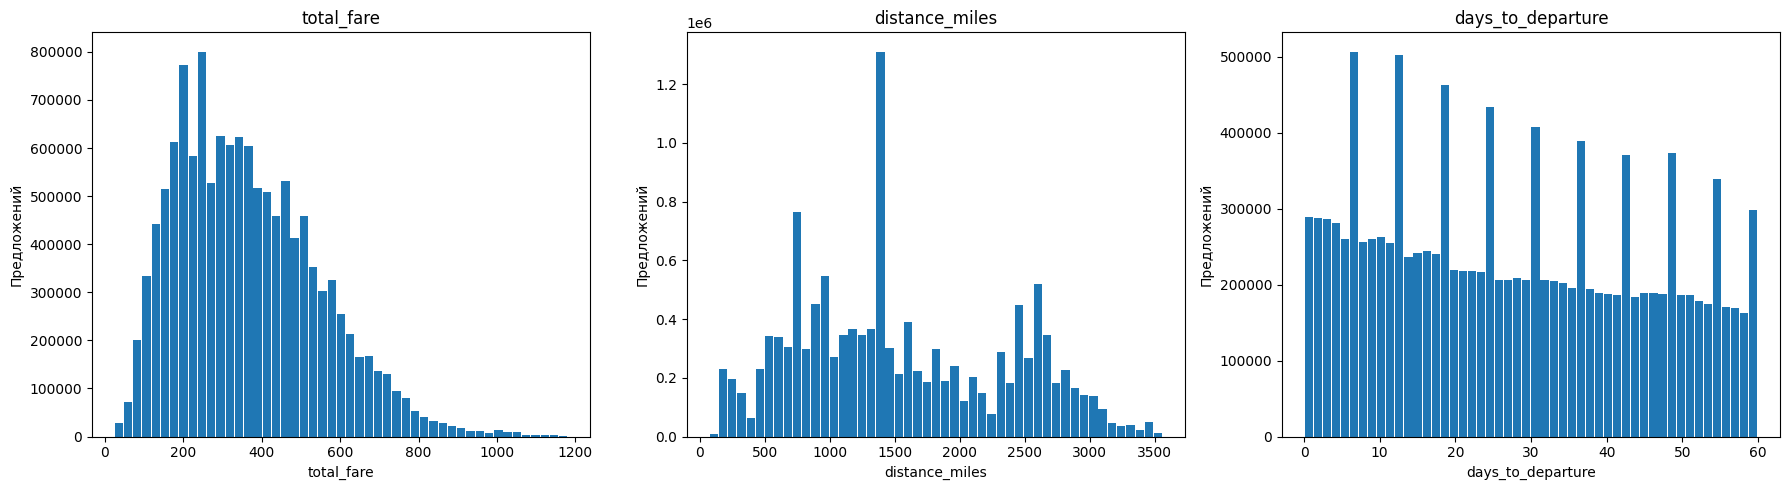

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["total_fare", "distance_miles", "days_to_departure"]):
    maximum = clean.agg(F.max(name)).first()[0]
    assert maximum > 0, name
    width = maximum / 50
    rows = (clean.withColumn("bin", F.least(F.floor(F.col(name) / width), F.lit(49)).cast("int"))
            .groupBy("bin").count().orderBy("bin").collect())
    bins = pd.DataFrame([{"x": (row["bin"] + 0.5) * width, "count": row["count"]} for row in rows])
    ax.bar(bins["x"], bins["count"], width=width * 0.9)
    ax.set_title(name)
    ax.set_xlabel(name)
    ax.set_ylabel("Предложений")
plt.tight_layout()
plt.show()


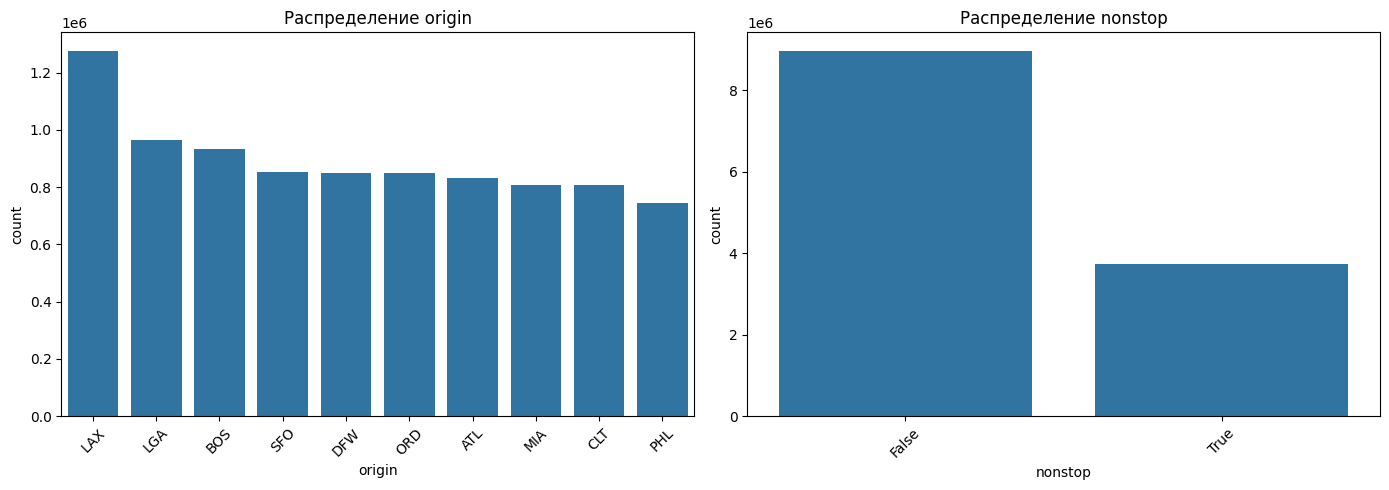

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["origin", "nonstop"]):
    counts = clean.groupBy(name).count().orderBy(F.desc("count")).limit(10).toPandas()
    counts[name] = counts[name].astype(str)
    sns.barplot(data=counts, x=name, y="count", ax=ax)
    ax.set_title(f"Распределение {name}")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


### 6. Корреляции количественных признаков

Матрица Пирсона рассчитывается одной Spark-агрегацией. `base_fare` входит в `total_fare`, поэтому их высокая корреляция ожидаема и не трактуется как независимое объяснение цены. Корреляции не означают причинность.


26/11/19 22:54:22 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,total_fare,base_fare,distance_miles,days_to_departure,seats_remaining
total_fare,1.000000,0.995573,0.603935,0.077739,0.037437
base_fare,0.995573,1.000000,0.592677,0.075409,0.082912
distance_miles,0.603935,0.592677,1.000000,-0.010805,-0.043818
days_to_departure,0.077739,0.075409,-0.010805,1.000000,0.145297
seats_remaining,0.037437,0.082912,-0.043818,0.145297,1.000000


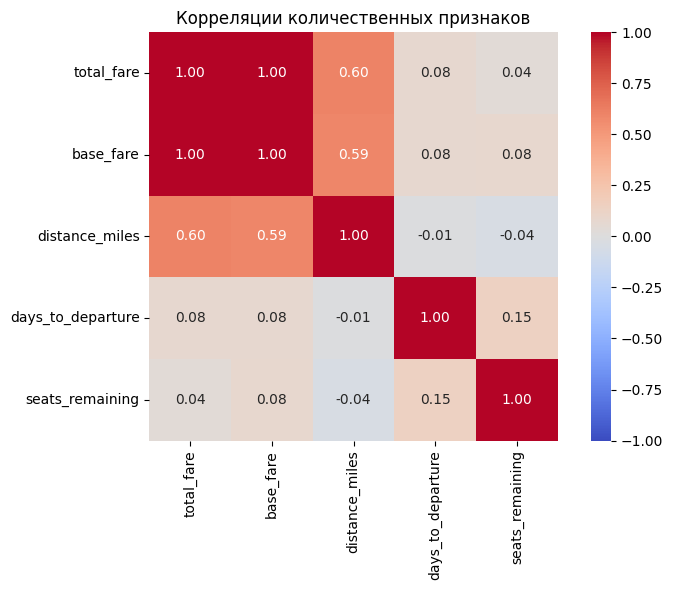

In [11]:
correlation_columns = ["total_fare", "base_fare", "distance_miles", "days_to_departure", "seats_remaining"]
pairs = [(a, b) for i, a in enumerate(correlation_columns) for b in correlation_columns[i+1:]]
corr_row = clean.agg(*[F.corr(a, b).alias(f"{a}__{b}") for a, b in pairs]).first().asDict()
matrix = pd.DataFrame(1.0, index=correlation_columns, columns=correlation_columns)
for a, b in pairs:
    value = corr_row[f"{a}__{b}"]
    matrix.loc[a, b] = value
    matrix.loc[b, a] = value
display(matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(matrix.astype(float), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", square=True)
plt.title("Корреляции количественных признаков")
plt.tight_layout()
plt.show()


### 7. Сохранение очищенных данных в таблицу Iceberg

Как в части 2 образца преподавателя, запишем итоговый датафрейм в таблицу Spark. Используется существующая база `statskevich_database`; исходные таблицы с автомобилями остаются без изменений. При повторном запуске уже созданная таблица проверяется, а повторная запись не выполняется.


In [12]:
table_name = "sobd_lab1_flight_prices_processed_table"
spark.catalog.setCurrentDatabase(database_name)
existing_tables = {table.name for table in spark.catalog.listTables(database_name)}
if table_name not in existing_tables:
    clean.writeTo(table_name).using("iceberg").create()
    print("Создана таблица:", f"{database_name}.{table_name}")
else:
    print("Таблица уже существует, повторная запись не требуется:", f"{database_name}.{table_name}")

saved = spark.table(table_name)
saved_n = saved.count()
assert saved_n == clean_n, f"В таблице {saved_n} строк, ожидалось {clean_n}"
assert [(f.name, f.dataType.simpleString()) for f in saved.schema.fields] == [
    (f.name, f.dataType.simpleString()) for f in clean.schema.fields
], "Схема сохранённой таблицы отличается от итогового датафрейма"
print("Строк в таблице:", saved_n)
saved.printSchema()
saved.show(5, truncate=False)
print("Таблицы базы:", [table.name for table in spark.catalog.listTables(database_name)])


Создана таблица: statskevich_database.sobd_lab1_flight_prices_processed_table


Строк в таблице: 12725169
root
 |-- legId: string (nullable = true)
 |-- search_date: date (nullable = true)
 |-- flight_date: date (nullable = true)
 |-- origin: string (nullable = true)
 |-- destination: string (nullable = true)
 |-- airlines: string (nullable = true)
 |-- basic_economy: boolean (nullable = true)
 |-- nonstop: boolean (nullable = true)
 |-- base_fare: double (nullable = true)
 |-- total_fare: double (nullable = true)
 |-- distance_miles: double (nullable = true)
 |-- seats_remaining: integer (nullable = true)
 |-- days_to_departure: integer (nullable = true)



+--------------------------------+-----------+-----------+------+-----------+-------------------------------------------------+-------------+-------+---------+----------+--------------+---------------+-----------------+
|legId                           |search_date|flight_date|origin|destination|airlines                                         |basic_economy|nonstop|base_fare|total_fare|distance_miles|seats_remaining|days_to_departure|
+--------------------------------+-----------+-----------+------+-----------+-------------------------------------------------+-------------+-------+---------+----------+--------------+---------------+-----------------+
|299f9d6c22aa24bc9a3d04f738db59bf|2022-04-21 |2022-05-16 |PHL   |MIA        |American Airlines||American Airlines             |false        |false  |161.86   |197.6     |1077.0        |1              |25               |
|5371f89133a4357ea89b6f51d5532958|2022-04-21 |2022-05-16 |PHL   |MIA        |American Airlines||American Airlines       

Таблицы базы: ['sobd_lab1_table', 'sobd_lab1_processed_table', 'sobd_lab1_flight_prices_processed_table']


### 8. Проверка результата

Проверяется объём исходного файла, число строк, отсутствие пропусков и значений за установленные пределы в ключевых полях, а также число записей в новой таблице Iceberg.


In [13]:
assert source_size >= 3 * 1024**3
assert raw_n >= valid_n >= clean_n > 0
checks = clean.agg(
    F.sum(F.when(F.col("total_fare").isNull() | F.isnan("total_fare") | (F.col("total_fare") <= 0) | (F.col("total_fare") > limits["total_fare"]), 1).otherwise(0)).alias("total_fare"),
    F.sum(F.when(F.col("distance_miles").isNull() | F.isnan("distance_miles") | (F.col("distance_miles") < 0) | (F.col("distance_miles") > limits["distance_miles"]), 1).otherwise(0)).alias("distance_miles"),
    F.sum(F.when(F.col("days_to_departure").isNull() | ~F.col("days_to_departure").between(0, 365), 1).otherwise(0)).alias("days_to_departure"),
).first().asDict()
assert all(value == 0 for value in checks.values()), checks
print("Проверка пройдена. Итоговых строк:", clean_n)
print("Ошибки ключевых полей:", checks)
assert saved_n == clean_n
print("Таблицы базы:", [t.name for t in spark.catalog.listTables(database_name)])
clean.unpersist()
valid.unpersist()


Проверка пройдена. Итоговых строк: 12725169
Ошибки ключевых полей: {'total_fare': 0, 'distance_miles': 0, 'days_to_departure': 0}


Таблицы базы: ['sobd_lab1_table', 'sobd_lab1_processed_table', 'sobd_lab1_flight_prices_processed_table']


DataFrame[legId: string, search_date: date, flight_date: date, origin: string, destination: string, airlines: string, basic_economy: boolean, nonstop: boolean, base_fare: double, total_fare: double, distance_miles: double, seats_remaining: int, days_to_departure: int]